# IND320 Compulsory Assignment 3

## Name: Vasilii Anderson

## Project Links

**GitHub repository:**  
https://github.com/VasiliiAnderson/ind320-project

**Streamlit application:**  
https://vasilii-ind320.streamlit.app/

## 1. Setup and Imports

In [23]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd
import time

## 2. NVE Region Shapefiles

### 2.1 Load the shapefile

In [6]:
shapefile_path = Path("C:/dev/IND320/project/data/shapefiles/nve_regions/NVE_Region.shp")

gdf = gpd.read_file(shapefile_path)

print(gdf.columns)
print(gdf.crs)
display(gdf.head())

Index(['OBJECTID', 'REGION', 'REGIONNAVN', 'POSTNUMMER', 'POSTSTED',
       'BESÃKSADR', 'ADRESSE', 'geometry'],
      dtype='str')
EPSG:25833


,OBJECTID,REGION,REGIONNAVN,POSTNUMMER,POSTSTED,BESÃKSADR,ADRESSE,geometry
0,1.0,RV,Region Vest,6801,FÃ¸rde,Naustdalsveien 1B,Postboks 53,"POLYGON ((193105.76 6929797.839, 191705.75 692..."
1,2.0,RM,Region Midt-Norge,7030,Trondheim,"Abelsgate 9, Trondheim",Abelsgate 9,"POLYGON ((391250 7388620, 392270 7386790, 3937..."
2,3.0,RN,Region Nord,8514,Narvik,Kongensgate 52-54,Kongensgate 52-54,"POLYGON ((1109096.413 7844647.502, 1105115.343..."
3,4.0,RÃ,Region Ãst,2307,Hamar,Vangsvegen 73,Postboks 4223,"POLYGON ((253748.22 6678130.91, 253645.58 6678..."
4,5.0,RS,Region SÃ¸r,3103,TÃ¸nsberg,Anton Jenssens gate 7,Postboks 2124,"POLYGON ((253748.22 6678130.91, 253917.63 6677..."


In [7]:
print(gdf["REGION"].unique())

<ArrowStringArray>
['RV', 'RM', 'RN', 'RÃ', 'RS']
Length: 5, dtype: str


### 2.2 Inspect the regions

c:\dev\IND320\project\.venv\Lib\site-packages\geopandas\plotting.py:1339: UserWarning: Glyph 152 (\x98) missing from font(s) DejaVu Sans.
  ax.figure.canvas.draw_idle()
c:\dev\IND320\project\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 152 (\x98) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


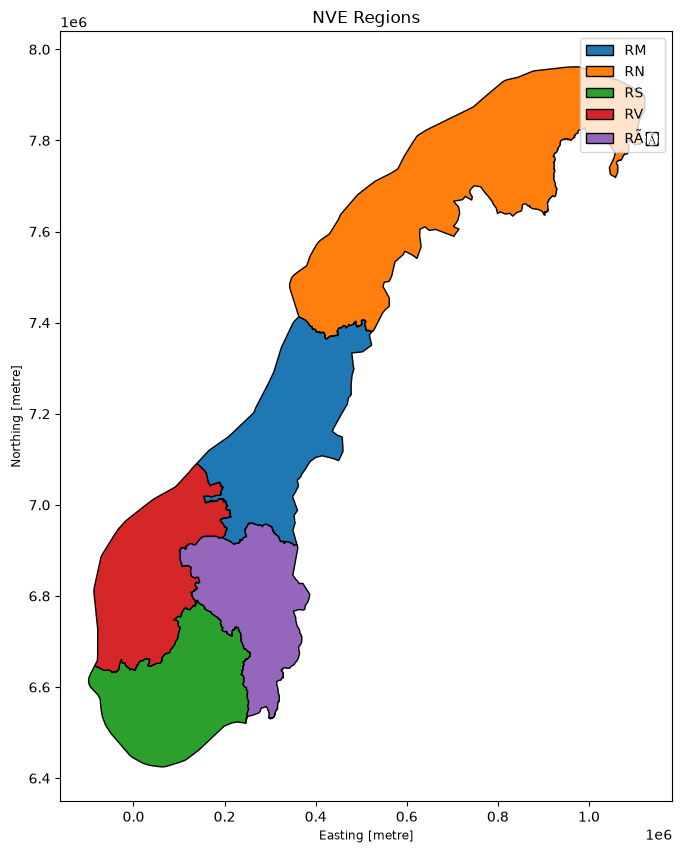

In [8]:

gdf.plot(
    column="REGION",
    legend=True,
    figsize=(8, 10),
    edgecolor="black"
)

plt.title("NVE Regions")
plt.show()

### 2.3 Randomly sample 1000 locations per region

In [9]:
K = 1000

points_per_region = gdf["geometry"].sample_points(
    size=K,
    random_state=42
)

In [10]:
points_wgs84 = points_per_region.to_crs(epsg=4326)

In [11]:
coordinates = []

for idx, multipoint in points_wgs84.items():

    region_name = gdf.loc[idx, "REGION"]

    for point in multipoint.geoms:
        coordinates.append({
            "region": region_name,
            "latitude": point.y,
            "longitude": point.x
        })

coordinates_df = pd.DataFrame(coordinates)

display(coordinates_df.head())
print(coordinates_df["region"].value_counts())

,region,latitude,longitude
0,RV,62.783756,5.903380
1,RV,61.418886,6.404620
2,RV,61.298972,7.934215
3,RV,60.895659,6.120993
4,RV,60.245130,6.535042


region
RV     1000
RM     1000
RN     1000
RÃ    1000
RS     1000
Name: count, dtype: int64


### 2.5 Electricity bidding areas

In [13]:
list(Path("../data/shapefiles/elspot").glob("*.shp"))

[WindowsPath('../data/shapefiles/elspot/Budområder.shp')]

In [14]:
elspot_path = Path("../data/shapefiles/elspot/Budområder.shp")

elspot_gdf = gpd.read_file(elspot_path)

print(elspot_gdf.columns)
print(elspot_gdf.crs)
display(elspot_gdf.head())

Index(['objectid', 'budomr', 'globalid', 'st_area(sh', 'st_perimet',
       'geometry'],
      dtype='str')
EPSG:25833


,objectid,budomr,globalid,st_area(sh,st_perimet,geometry
0,1.0,NO 1,NaN,6.052902e+10,1.657761e+06,"POLYGON ((337473.63 6970542.97, 337711.9 69703..."
1,2.0,NO 2,NaN,6.875969e+10,1.256473e+06,"POLYGON ((-9833.91 6726499.86, -9836 6726404.0..."
2,3.0,NO 3,NaN,1.042199e+11,1.773323e+06,"POLYGON ((308588.7 7261519.43, 313576.63 72590..."
3,4.0,NO 4,NaN,2.032500e+11,3.385499e+06,"POLYGON ((973920.93 7962739.19, 974922.77 7962..."
4,5.0,NO 5,NaN,3.334870e+10,1.106762e+06,"POLYGON ((101466.43 6881318.54, 101525.43 6881..."


In [15]:
print(elspot_gdf["budomr"].unique())

<ArrowStringArray>
['NO 1', 'NO 2', 'NO 3', 'NO 4', 'NO 5']
Length: 5, dtype: str


In [16]:
elspot_gdf["region"] = (
    elspot_gdf["budomr"]
    .str.replace(" ", "", regex=False)
)

print(elspot_gdf["region"].unique())

<ArrowStringArray>
['NO1', 'NO2', 'NO3', 'NO4', 'NO5']
Length: 5, dtype: str


In [17]:
K = 1000

elspot_points = elspot_gdf["geometry"].sample_points(
    size=K,
    random_state=42
)

elspot_points_wgs84 = elspot_points.to_crs(epsg=4326)

In [18]:
coordinates_elspot = []

for idx, multipoint in elspot_points_wgs84.items():

    region_name = elspot_gdf.loc[idx, "region"]

    for point in multipoint.geoms:
        coordinates_elspot.append({
            "region": region_name,
            "latitude": point.y,
            "longitude": point.x
        })

coordinates_elspot_df = pd.DataFrame(coordinates_elspot)

display(coordinates_elspot_df.head())
print(coordinates_elspot_df["region"].value_counts())

,region,latitude,longitude
0,NO1,59.961401,9.300614
1,NO1,59.798018,11.262229
2,NO1,61.408917,12.523235
3,NO1,60.881327,10.958908
4,NO1,60.892870,10.771955


region
NO1    1000
NO2    1000
NO3    1000
NO4    1000
NO5    1000
Name: count, dtype: int64


In [19]:
no3_coordinates = coordinates_elspot_df[
    coordinates_elspot_df["region"] == "NO3"
].reset_index(drop=True)

display(no3_coordinates.head())
print(len(no3_coordinates))

,region,latitude,longitude
0,NO3,65.188738,10.372535
1,NO3,64.911047,10.152153
2,NO3,64.205598,13.043099
3,NO3,63.813892,11.415449
4,NO3,63.092458,9.203733


1000


## 3. Open-Meteo ERA5 Weather Data

Historical hourly weather data are retrieved from the Open-Meteo Historical Weather API using the ERA5 reanalysis model. The sampled coordinates are used to represent the selected Norwegian region.

In [20]:
import requests
import pandas as pd

ARCHIVE_URL = "https://archive-api.open-meteo.com/v1/archive"

# Select one of the sampled locations in NO3
test_point = no3_coordinates.iloc[0]

params = {
    "latitude": test_point["latitude"],
    "longitude": test_point["longitude"],
    "start_date": "2024-01-01",
    "end_date": "2024-01-03",
    "hourly": "temperature_2m,precipitation,snowfall",
    "models": "era5",
    "timezone": "UTC",
}

response = requests.get(
    ARCHIVE_URL,
    params=params,
    timeout=60
)

response.raise_for_status()

data = response.json()

print("HTTP status:", response.status_code)
print("Returned latitude:", data["latitude"])
print("Returned longitude:", data["longitude"])

HTTP status: 200
Returned latitude: 65.25
Returned longitude: 10.25


In [21]:
weather_test = pd.DataFrame(data["hourly"])

weather_test["time"] = pd.to_datetime(weather_test["time"])

display(weather_test.head())
print(weather_test.shape)

,time,temperature_2m,precipitation,snowfall
0,2024-01-01 00:00:00,-2.1,0.0,0.0
1,2024-01-01 01:00:00,-2.2,0.0,0.0
2,2024-01-01 02:00:00,-2.0,0.0,0.0
3,2024-01-01 03:00:00,-2.0,0.0,0.0
4,2024-01-01 04:00:00,-1.9,0.0,0.0


(72, 4)


### 3.2 Weather download function

The function below retrieves hourly ERA5 weather data for a selected region and time interval. A random subset of the 1000 sampled locations is used to represent the region.

In [ ]:
ARCHIVE_URL = "https://archive-api.open-meteo.com/v1/archive"

WEATHER_VARIABLES = [
    "temperature_2m",
    "precipitation",
    "snowfall",
]


def download_weather(
    region,
    start_date,
    end_date,
    locations,
    n_locations=10,
    random_state=42
):
    """
    Download hourly ERA5 weather data for sampled locations in a region.

    Parameters
    ----------
    region : str
        Region identifier, for example "NO3".
    start_date : str
        Start date in YYYY-MM-DD format.
    end_date : str
        End date in YYYY-MM-DD format.
    locations : pd.DataFrame
        DataFrame containing region, latitude and longitude.
    n_locations : int
        Number of sampled locations used for the download.
    random_state : int
        Random seed for reproducibility.

    Returns
    -------
    pd.DataFrame
        Hourly weather observations for all selected locations.
    """

    # Select coordinates belonging to the requested region
    region_points = locations[
        locations["region"] == region
    ]

    if region_points.empty:
        raise ValueError(f"No coordinates found for region {region}")

    # Randomly select locations from the 1000 sampled points
    selected_points = region_points.sample(
        n=min(n_locations, len(region_points)),
        random_state=random_state
    )

    weather_frames = []

    for location_id, (_, point) in enumerate(selected_points.iterrows()):

        params = {
            "latitude": point["latitude"],
            "longitude": point["longitude"],
            "start_date": start_date,
            "end_date": end_date,
            "hourly": ",".join(WEATHER_VARIABLES),
            "models": "era5",
            "timezone": "UTC",
        }

        response = requests.get(
            ARCHIVE_URL,
            params=params,
            timeout=120
        )

        response.raise_for_status()

        data = response.json()

        hourly = pd.DataFrame(data["hourly"])
        hourly["time"] = pd.to_datetime(hourly["time"])
        hourly["location_id"] = location_id
        hourly["latitude"] = point["latitude"]
        hourly["longitude"] = point["longitude"]

        weather_frames.append(hourly)

        # Small pause to avoid sending requests too quickly
        time.sleep(0.2)

    return pd.concat(weather_frames, ignore_index=True)

In [24]:
weather_test_multi = download_weather(
    region="NO3",
    start_date="2024-01-01",
    end_date="2024-01-03",
    locations=coordinates_elspot_df,
    n_locations=10
)

display(weather_test_multi.head())

print("Rows:", len(weather_test_multi))
print("Locations:", weather_test_multi["location_id"].nunique())

,time,temperature_2m,precipitation,snowfall,location_id,latitude,longitude
0,2024-01-01 00:00:00,-11.7,0.1,0.07,0,62.042426,9.393882
1,2024-01-01 01:00:00,-11.7,0.1,0.07,0,62.042426,9.393882
2,2024-01-01 02:00:00,-11.6,0.1,0.07,0,62.042426,9.393882
3,2024-01-01 03:00:00,-11.9,0.1,0.07,0,62.042426,9.393882
4,2024-01-01 04:00:00,-11.8,0.1,0.07,0,62.042426,9.393882


Rows: 720
Locations: 10


In [25]:
weather_no3_2024 = download_weather(
    region="NO3",
    start_date="2024-01-01",
    end_date="2024-12-31",
    locations=coordinates_elspot_df,
    n_locations=10
)

print("Rows:", len(weather_no3_2024))
print("Locations:", weather_no3_2024["location_id"].nunique())
display(weather_no3_2024.head())

Rows: 87840
Locations: 10


,time,temperature_2m,precipitation,snowfall,location_id,latitude,longitude
0,2024-01-01 00:00:00,-11.7,0.1,0.07,0,62.042426,9.393882
1,2024-01-01 01:00:00,-11.7,0.1,0.07,0,62.042426,9.393882
2,2024-01-01 02:00:00,-11.6,0.1,0.07,0,62.042426,9.393882
3,2024-01-01 03:00:00,-11.9,0.1,0.07,0,62.042426,9.393882
4,2024-01-01 04:00:00,-11.8,0.1,0.07,0,62.042426,9.393882


In [26]:
weather_no3_hourly = (
    weather_no3_2024
    .groupby("time", as_index=False)
    .agg({
        "temperature_2m": "mean",
        "precipitation": "mean",
        "snowfall": "mean"
    })
)

display(weather_no3_hourly.head())
print(weather_no3_hourly.shape)

,time,temperature_2m,precipitation,snowfall
0,2024-01-01 00:00:00,-2.38,0.01,0.007
1,2024-01-01 01:00:00,-2.49,0.01,0.007
2,2024-01-01 02:00:00,-2.47,0.01,0.007
3,2024-01-01 03:00:00,-2.54,0.01,0.007
4,2024-01-01 04:00:00,-2.55,0.01,0.007


(8784, 4)


In [27]:
weather_no3_hourly = weather_no3_hourly.rename(
    columns={
        "temperature_2m": "avg_temperature",
        "precipitation": "avg_precipitation",
        "snowfall": "avg_snowfall"
    }
)

## 4. Precipitation Outliers: DCT and Statistical Process Control

The average hourly precipitation is analysed for outliers using a Discrete Cosine Transform (DCT) high-pass filter. The high-pass filtered values are used to estimate seasonally adjusted variations (SATV). Robust statistics are then used to construct Statistical Process Control (SPC) boundaries.

In [28]:
precip_series = (
    weather_no3_hourly
    .set_index("time")["avg_precipitation"]
    .rename("Precipitation (mm)")
)

display(precip_series.head())

time
2024-01-01 00:00:00    0.01
2024-01-01 01:00:00    0.01
2024-01-01 02:00:00    0.01
2024-01-01 03:00:00    0.01
2024-01-01 04:00:00    0.01
Name: Precipitation (mm), dtype: float64

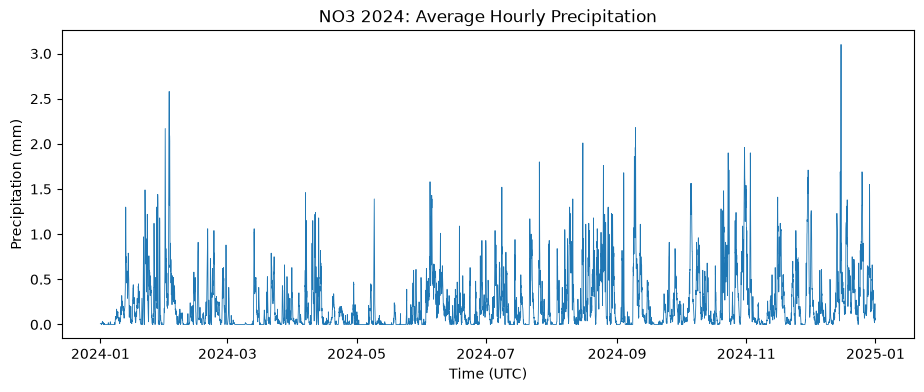

In [29]:
fig, ax = plt.subplots(figsize=(11, 4))

ax.plot(precip_series.index, precip_series, linewidth=0.6)

ax.set_title("NO3 2024: Average Hourly Precipitation")
ax.set_xlabel("Time (UTC)")
ax.set_ylabel("Precipitation (mm)")

plt.show()

In [30]:
import numpy as np

from scipy.fft import dct, idct
from scipy.stats import median_abs_deviation


def _samples_per_year(index):
    """Calculate the number of observations per year from the time index."""
    
    step = pd.Series(index).diff().median()
    
    return pd.Timedelta(days=365.25) / step


def spc_outliers(series, cutoff=12, n_sd=3):
    """
    Detect precipitation outliers using a DCT high-pass filter
    and robust Statistical Process Control boundaries.

    Parameters
    ----------
    series : pd.Series
        Time series with a DatetimeIndex.
    cutoff : float
        DCT cut-off frequency in cycles per year.
    n_sd : float
        Number of robust standard deviations used for the SPC boundaries.

    Returns
    -------
    fig : matplotlib.figure.Figure
        Plot showing precipitation, SPC boundaries and outliers.
    summary : dict
        Summary statistics and identified outliers.
    """

    x = series.to_numpy(dtype=float)
    n = len(x)

    # Convert the frequency cut-off to a DCT coefficient index
    samples_per_year = _samples_per_year(series.index)
    k = int(round(2 * n * cutoff / samples_per_year))

    # DCT high-pass filtering:
    # remove the low-frequency components representing slow seasonal variation
    coefficients = dct(x, type=2, norm="ortho")
    coefficients[:k] = 0

    # Seasonally adjusted variations (SATV)
    satv = idct(coefficients, type=2, norm="ortho")

    # The removed low-frequency component represents the seasonal level
    seasonal_level = x - satv

    # Robust centre and spread estimated from the SATV
    centre = np.median(satv)
    robust_sd = 1.4826 * median_abs_deviation(satv)

    # SPC boundaries around the seasonal level
    upper = seasonal_level + centre + n_sd * robust_sd
    lower = seasonal_level + centre - n_sd * robust_sd

    # Identify observations outside the boundaries
    is_outlier = (x > upper) | (x < lower)

    # Plot original precipitation, boundaries and outliers
    fig, ax = plt.subplots(figsize=(11, 4))

    ax.plot(
        series.index,
        x,
        linewidth=0.7,
        label="Precipitation"
    )

    ax.plot(
        series.index,
        upper,
        linestyle="--",
        linewidth=0.8,
        label="SPC boundaries"
    )

    ax.plot(
        series.index,
        lower,
        linestyle="--",
        linewidth=0.8
    )

    ax.scatter(
        series.index[is_outlier],
        x[is_outlier],
        s=10,
        label="Outliers"
    )

    ax.set_title(
        f"Precipitation Outliers "
        f"(DCT cut-off = {cutoff}/year, {n_sd} robust SD)"
    )
    ax.set_xlabel("Time (UTC)")
    ax.set_ylabel("Precipitation (mm)")
    ax.legend()

    fig.tight_layout()

    # Store information about the identified outliers
    outliers = pd.DataFrame(
        {
            "precipitation": x,
            "lower": lower,
            "upper": upper
        },
        index=series.index
    )[is_outlier]

    summary = {
        "n_outliers": int(is_outlier.sum()),
        "share": float(is_outlier.mean()),
        "above_upper": int((x > upper).sum()),
        "below_lower": int((x < lower).sum()),
        "robust_sd": float(robust_sd),
        "dct_coefficients_removed": k,
        "outliers": outliers
    }

    return fig, summary

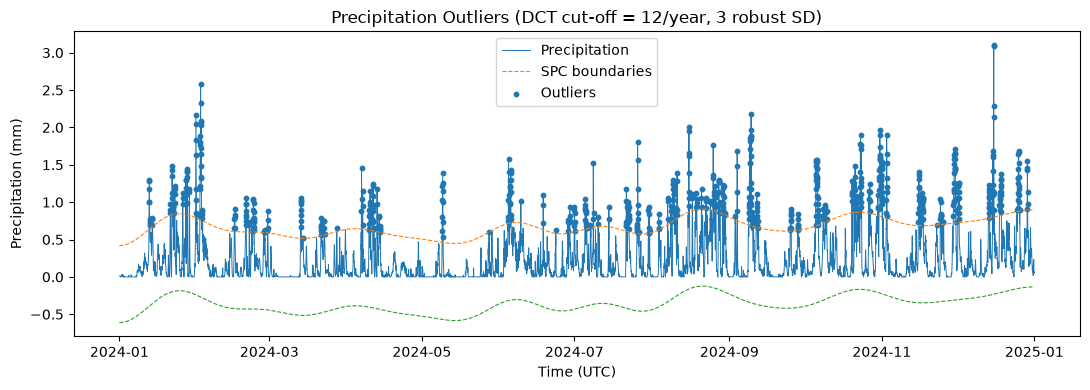

In [31]:
fig, summary = spc_outliers(
    precip_series,
    cutoff=12,
    n_sd=3
)

plt.show()

In [32]:
print("Number of outliers:", summary["n_outliers"])
print("Share of observations:", f"{summary['share']:.2%}")
print("Above upper boundary:", summary["above_upper"])
print("Below lower boundary:", summary["below_lower"])
print("Robust SD:", round(summary["robust_sd"], 4))
print("DCT coefficients removed:", summary["dct_coefficients_removed"])

Number of outliers: 730
Share of observations: 8.31%
Above upper boundary: 730
Below lower boundary: 0
Robust SD: 0.1719
DCT coefficients removed: 24


In [33]:
summary["outliers"].sort_values(
    "precipitation",
    ascending=False
).head(10)

,precipitation,lower,upper
time,,,
2024-12-15 18:00:00,3.10,-0.232726,0.798390
2024-12-15 17:00:00,3.09,-0.233052,0.798065
2024-02-02 12:00:00,2.58,-0.269040,0.762077
2024-02-02 11:00:00,2.33,-0.268366,0.762750
2024-12-15 19:00:00,2.29,-0.232400,0.798716
2024-09-09 17:00:00,2.18,-0.347734,0.683383
2024-01-31 15:00:00,2.17,-0.239945,0.791171
2024-12-15 16:00:00,2.14,-0.233376,0.797740
2024-02-02 17:00:00,2.09,-0.272421,0.758696


The DCT-based SPC analysis identified 730 precipitation observations as outliers, corresponding to 8.31% of the hourly observations. All detected outliers were above the upper SPC boundary, which is reasonable since precipitation is non-negative and extreme events mainly occur as unusually high precipitation.

## 5. Temperature Anomalies using Local Outlier Factor

Local Outlier Factor (LOF) is used to identify unusual temperature observations. The contamination parameter controls the expected proportion of anomalies and defaults to 1%.

In [34]:
temperature_series = (
    weather_no3_hourly
    .set_index("time")["avg_temperature"]
    .rename("Temperature (°C)")
)

display(temperature_series.head())

time
2024-01-01 00:00:00   -2.38
2024-01-01 01:00:00   -2.49
2024-01-01 02:00:00   -2.47
2024-01-01 03:00:00   -2.54
2024-01-01 04:00:00   -2.55
Name: Temperature (°C), dtype: float64

In [35]:
from sklearn.neighbors import LocalOutlierFactor


def temperature_lof(series, contamination=0.01, n_neighbors=20):
    """
    Detect temperature anomalies using Local Outlier Factor.

    Parameters
    ----------
    series : pd.Series
        Temperature time series with a DatetimeIndex.
    contamination : float
        Expected proportion of anomalies. Default is 1%.
    n_neighbors : int
        Number of neighbouring observations used by LOF.

    Returns
    -------
    fig : matplotlib.figure.Figure
        Temperature plot with anomalies highlighted.
    summary : dict
        Summary of detected anomalies.
    """

    # LOF expects a two-dimensional input array
    X = series.to_numpy().reshape(-1, 1)

    lof = LocalOutlierFactor(
        n_neighbors=n_neighbors,
        contamination=contamination
    )

    labels = lof.fit_predict(X)

    # LOF returns -1 for anomalies and 1 for normal observations
    is_anomaly = labels == -1

    fig, ax = plt.subplots(figsize=(11, 4))

    ax.plot(
        series.index,
        series,
        linewidth=0.7,
        label="Temperature"
    )

    ax.scatter(
        series.index[is_anomaly],
        series[is_anomaly],
        s=15,
        label="LOF anomalies"
    )

    ax.set_title(
        f"NO3 Temperature Anomalies "
        f"(LOF, contamination={contamination:.1%})"
    )
    ax.set_xlabel("Time (UTC)")
    ax.set_ylabel("Temperature (°C)")
    ax.legend()

    fig.tight_layout()

    anomalies = pd.DataFrame(
        {
            "temperature": series[is_anomaly],
            "lof_score": lof.negative_outlier_factor_[is_anomaly]
        }
    )

    summary = {
        "n_anomalies": int(is_anomaly.sum()),
        "share": float(is_anomaly.mean()),
        "anomalies": anomalies
    }

    return fig, summary

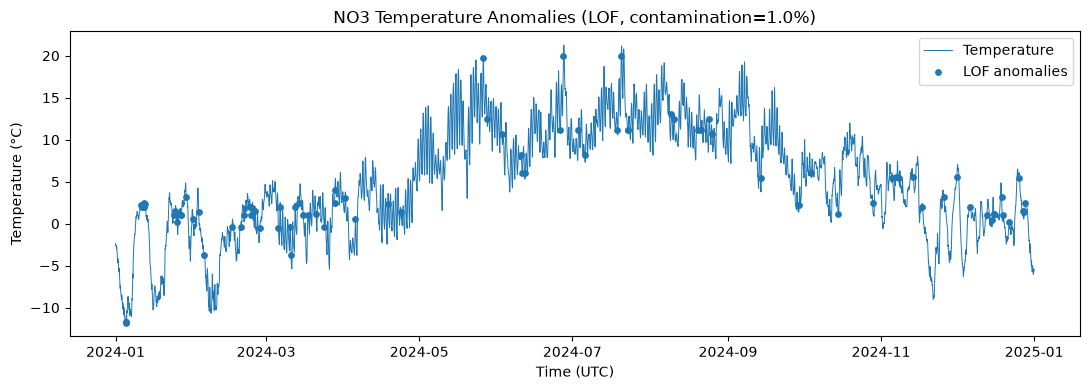

In [36]:
fig, temperature_summary = temperature_lof(
    temperature_series,
    contamination=0.01
)

plt.show()

In [37]:
print("Number of anomalies:", temperature_summary["n_anomalies"])
print(
    "Share of observations:",
    f"{temperature_summary['share']:.2%}"
)

display(
    temperature_summary["anomalies"]
    .sort_values("lof_score")
    .head(10)
)

Number of anomalies: 88
Share of observations: 1.00%


,temperature,lof_score
time,,
2024-08-19 22:00:00,11.17,-1.484128
2024-11-06 22:00:00,5.50,-1.424458
2024-11-13 18:00:00,5.50,-1.424458
2024-07-23 02:00:00,11.16,-1.414776
2024-07-23 05:00:00,11.16,-1.414776
2024-12-22 02:00:00,0.20,-1.362288
2024-01-25 14:00:00,0.20,-1.362288
2024-04-18 18:00:00,2.31,-1.350370
2024-01-05 02:00:00,-11.78,-1.349798


The LOF analysis identified 88 temperature anomalies, corresponding to 1.00% of the hourly observations, as specified by the contamination parameter. LOF identifies observations based on their local density relative to neighbouring values, so detected anomalies are not necessarily limited to the highest or lowest temperatures.

## 6. STL Decomposition of Reservoir Filling Level

Seasonal-Trend decomposition using LOESS (STL) is applied to the reservoir filling level to separate the observed time series into trend, seasonal and residual components.

## 6. STL Decomposition of Reservoir Filling Level

The reservoir filling level for area NO3 is decomposed into trend, seasonal and residual components using Seasonal-Trend decomposition with LOESS (STL).

In [39]:
NVE_DATA_URL = (
    "https://biapi.nve.no/magasinstatistikk/"
    "api/Magasinstatistikk/HentOffentligData"
)

response = requests.get(NVE_DATA_URL, timeout=30)
response.raise_for_status()

reservoir_df = pd.DataFrame(response.json())

reservoir_df = reservoir_df.rename(
    columns={
        "dato_Id": "date",
        "omrType": "area_type",
        "omrnr": "area_number",
        "fyllingsgrad": "fill_level",
        "kapasitet_TWh": "capacity_twh",
        "fylling_TWh": "stored_energy_twh",
    }
)

reservoir_df["date"] = pd.to_datetime(reservoir_df["date"])

print(reservoir_df.columns)
display(reservoir_df.head())

Index(['date', 'area_type', 'area_number', 'iso_aar', 'iso_uke', 'fill_level',
       'capacity_twh', 'stored_energy_twh', 'neste_Publiseringsdato',
       'fyllingsgrad_forrige_uke', 'endring_fyllingsgrad'],
      dtype='str')


,date,area_type,area_number,iso_aar,iso_uke,fill_level,capacity_twh,stored_energy_twh,neste_Publiseringsdato,fyllingsgrad_forrige_uke,endring_fyllingsgrad
0,2020-11-15,EL,1,2020,46,0.974361,6.003264,5.849344,2020-11-25T13:00:00,0.997406,-0.023046
1,2011-08-28,EL,4,2011,34,0.786499,21.079208,16.578772,0001-01-01T00:00:00,0.787193,-0.000694
2,1998-07-05,EL,3,1998,27,0.793969,8.920932,7.082947,0001-01-01T00:00:00,0.733812,0.060157
3,2011-03-27,EL,4,2011,12,0.300820,21.079208,6.341054,0001-01-01T00:00:00,0.311122,-0.010301
4,2017-11-05,EL,4,2017,44,0.794520,21.079208,16.747847,0001-01-01T00:00:00,0.804085,-0.009565


In [40]:
# Select reservoir filling level for electricity area NO3
fill_no3 = (
    reservoir_df[
        (reservoir_df["area_type"] == "EL")
        & (reservoir_df["area_number"] == 3)
    ][["date", "fill_level"]]
    .dropna()
    .sort_values("date")
    .drop_duplicates(subset="date")
    .set_index("date")["fill_level"]
)

print(fill_no3.head())
print(fill_no3.tail())
print("Number of observations:", len(fill_no3))

date
1995-01-08    0.602376
1995-01-15    0.569943
1995-01-22    0.542203
1995-01-29    0.508148
1995-02-05    0.473883
Name: fill_level, dtype: float64
date
2026-10-04    0.718754
2026-10-11    0.725240
2026-10-18    0.724940
2026-10-25    0.717647
2026-11-01    0.720149
Name: fill_level, dtype: float64
Number of observations: 1661


In [41]:
print(fill_no3.index.to_series().diff().value_counts().head())

date
7 days    1660
Name: count, dtype: int64


In [42]:
from statsmodels.tsa.seasonal import STL


def plot_stl(
    series,
    seasonal=13,
    trend=53,
    robust=True
):
    """
    Perform STL decomposition of a weekly reservoir filling-level series.

    Parameters
    ----------
    series : pd.Series
        Weekly filling-level observations with a DatetimeIndex.
    seasonal : int
        Length of the seasonal smoother. Must be an odd integer.
    trend : int
        Length of the trend smoother. Must be an odd integer.
    robust : bool
        Whether robust fitting should be used.

    Returns
    -------
    fig : matplotlib.figure.Figure
        STL decomposition plot.
    """

    # Annual seasonality for weekly reservoir data
    stl = STL(
        series,
        period=52,
        seasonal=seasonal,
        trend=trend,
        robust=robust
    )

    result = stl.fit()

    fig = result.plot()
    fig.set_size_inches(11, 8)

    fig.suptitle(
        "STL Decomposition of Reservoir Filling Level – NO3",
        y=1.02
    )

    fig.tight_layout()

    return fig

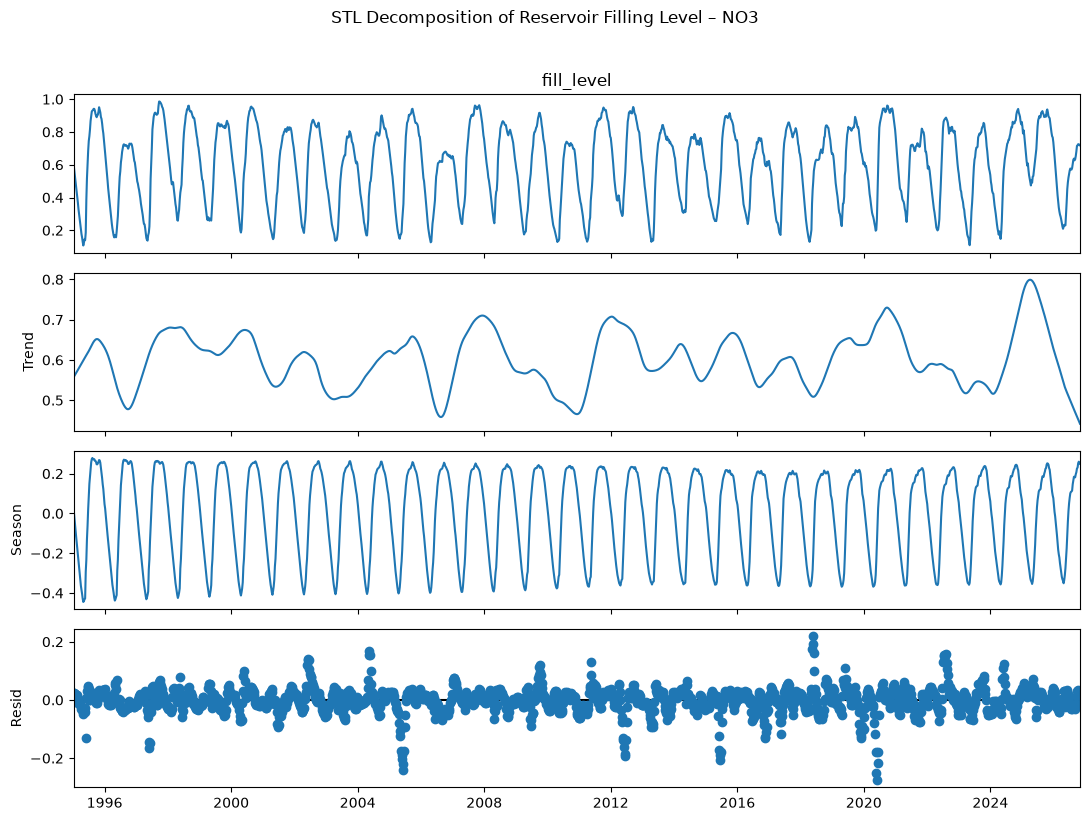

In [43]:
fig = plot_stl(
    fill_no3,
    seasonal=13,
    trend=53,
    robust=True
)

plt.show()

## 7. Spectrogram of Reservoir Filling Level

A spectrogram is used to investigate how the frequency content of the reservoir filling-level time series changes over time. Since the observations are weekly, frequencies are expressed in cycles per year.

In [46]:
from scipy.signal import spectrogram


def plot_spectrogram(
    series,
    window_length=104,
    overlap=52
):
    """
    Create a spectrogram of weekly reservoir filling-level data.

    Parameters
    ----------
    series : pd.Series
        Weekly filling-level observations.
    window_length : int
        Number of weekly observations in each analysis window.
        Default is 104 weeks (approximately two years).
    overlap : int
        Number of overlapping observations between windows.
        Default is 52 weeks (approximately one year).

    Returns
    -------
    fig : matplotlib.figure.Figure
        Spectrogram plot.
    """

    values = series.to_numpy(dtype=float)

    frequencies, times, power = spectrogram(
        values,
        fs=52,  # 52 observations per year
        nperseg=window_length,
        noverlap=overlap
    )

    fig, ax = plt.subplots(figsize=(11, 5))

    mesh = ax.pcolormesh(
    times,
    frequencies,
    power,
    shading="auto"
    )   

    ax.set_title(
        "Spectrogram of Reservoir Filling Level – NO3"
    )
    ax.set_xlabel("Time (years from start)")
    ax.set_ylabel("Frequency (cycles per year)")

    fig.colorbar(
        mesh,
        ax=ax,
        label="Power"
    )

    fig.tight_layout()

    return fig

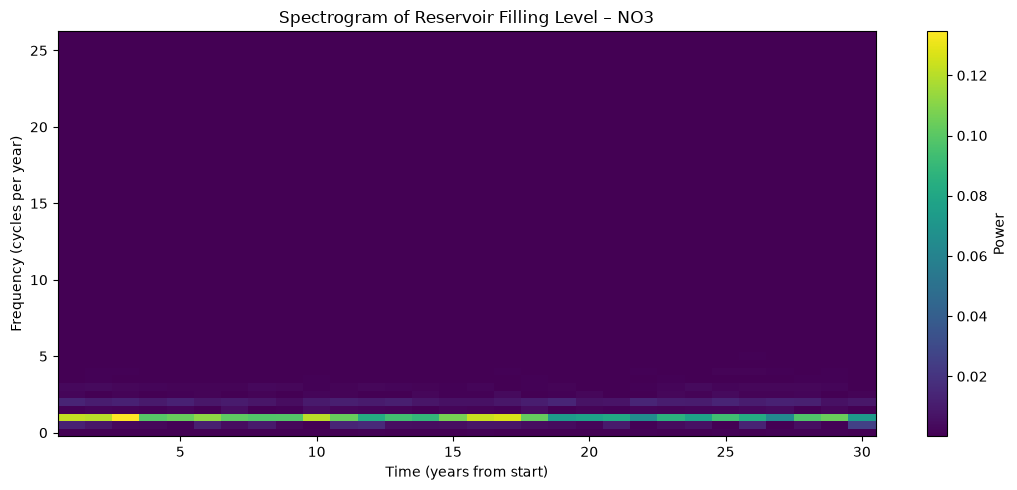

In [47]:
fig = plot_spectrogram(
    fill_no3,
    window_length=104,
    overlap=52
)

plt.show()